# 02 · Train PACE and MFM

**Goal:** run both stages of both methods on a small Ocean example, then inspect checkpoints, held-out metrics and plots.

This is a **CPU tutorial**, with 24 particles per snapshot and a few epochs. Its purpose is to teach the workflow; these numbers must not be used as a method ranking or a reproduction of the paper. Training logs and checkpoints go into `results/notebook_demo/`.

PACE uses a tangent-geometry bridge and iterative rematching. MFM uses a LAND-metric bridge. Both distill a Stage 2 velocity field.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'train.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'train.py').exists(), 'Open this notebook from PACE/ or PACE/notebooks/.'
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import torch
torch.set_num_threads(1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('PACE workspace:', ROOT.name)


PACE workspace: PACE


In [2]:
import subprocess
OUTPUT = ROOT/'results/notebook_demo'
OUTPUT.mkdir(parents=True, exist_ok=True)
for method in ['pace', 'mfm']:
    cmd = [sys.executable, 'train.py', f'experiment=oceans_positions_{method}_ode',
           'trainer=cpu', 'epochs=2', 'samples_per_timepoint=24', 'batch_size=24',
           'enable_progress_bar=false', f'working_dir={OUTPUT}']
    cmd += (['total_epochs_stage1=3', 'rematch_every=1', 'stage1_batch_size=24', 'T_steps=3', 't_probe_steps=3']
            if method == 'pace' else ['epochs_geopath=2'])
    with (OUTPUT/f'{method}.log').open('w') as log:
        result = subprocess.run(cmd, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
    if result.returncode:
        print((OUTPUT/f'{method}.log').read_text()[-8000:])
        raise RuntimeError(f'{method} training failed; see results/notebook_demo/{method}.log')
    print(f'{method.upper()}: both stages finished.')
RUN_ROOT = OUTPUT/'results/oceans_positions_dim2_test1-3-5-7'


PACE: both stages finished.


MFM: both stages finished.


## Read the correct evaluation rows

Each `ode_rollout` starts from the observed training snapshot immediately before a held-out time, then integrates through the bracket. Filter by both **stage** and **predictor**. Stage 1 bridge metrics and full-timecourse rollouts answer different questions.

In [3]:
tables = []
for method in ['pace', 'mfm']:
    frame = pd.read_csv(RUN_ROOT/method/'metrics/distribution_metrics.csv')
    frame = frame[(frame.stage == 'stage2') & (frame.predictor == 'ode_rollout')].copy()
    frame.insert(0, 'method', method.upper())
    tables.append(frame)
metrics = pd.concat(tables, ignore_index=True)
assert np.isfinite(metrics[['mmd', 'w1', 'w2']].to_numpy()).all()
display(metrics[['method', 'test_label', 'mmd', 'w1', 'w2']].round(4))

,method,test_label,mmd,w1,w2
0,PACE,1,1.0688,0.3626,0.3630
1,PACE,3,1.0961,0.4212,0.4226
2,PACE,5,1.0652,0.5625,0.5637
3,PACE,7,1.1176,0.6178,0.6198
4,MFM,1,1.0772,0.3565,0.3569
5,MFM,3,1.1003,0.4100,0.4115
6,MFM,5,1.0687,0.5729,0.5740
7,MFM,7,1.1145,0.6270,0.6289


PACE
Checkpoints: ['checkpoints/stage2_flow/flow-epoch=000.ckpt', 'checkpoints/stage2_flow/flow-epoch=001.ckpt', 'checkpoints/stage1_psi/last.ckpt', 'checkpoints/stage1_psi/psi-epoch=002.ckpt', 'checkpoints/stage1_psi/psi-epoch=001.ckpt', 'checkpoints/stage1_psi/psi-epoch=000.ckpt']


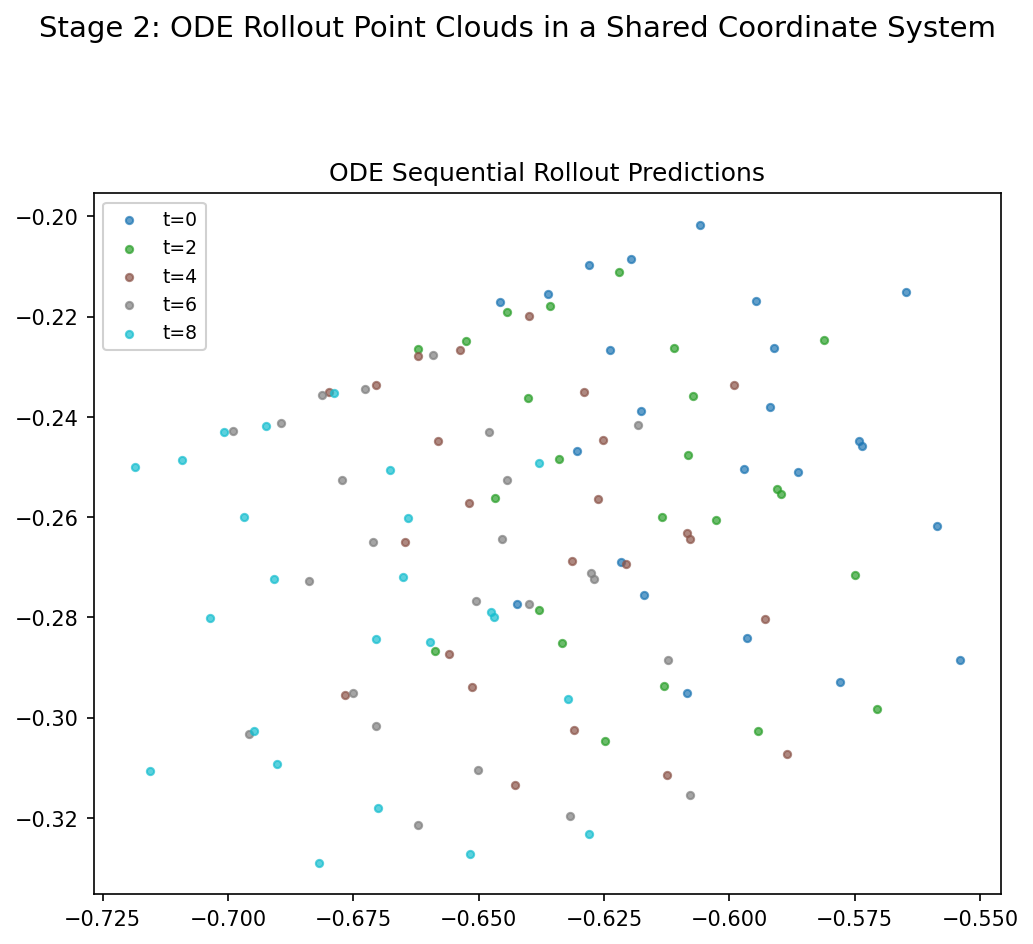

MFM
Checkpoints: ['checkpoints/stage2_flow/flow-epoch=000.ckpt', 'checkpoints/stage2_flow/flow-epoch=001.ckpt', 'checkpoints/stage1_geopath/geopath-epoch=001.ckpt', 'checkpoints/stage1_geopath/geopath-epoch=000.ckpt']


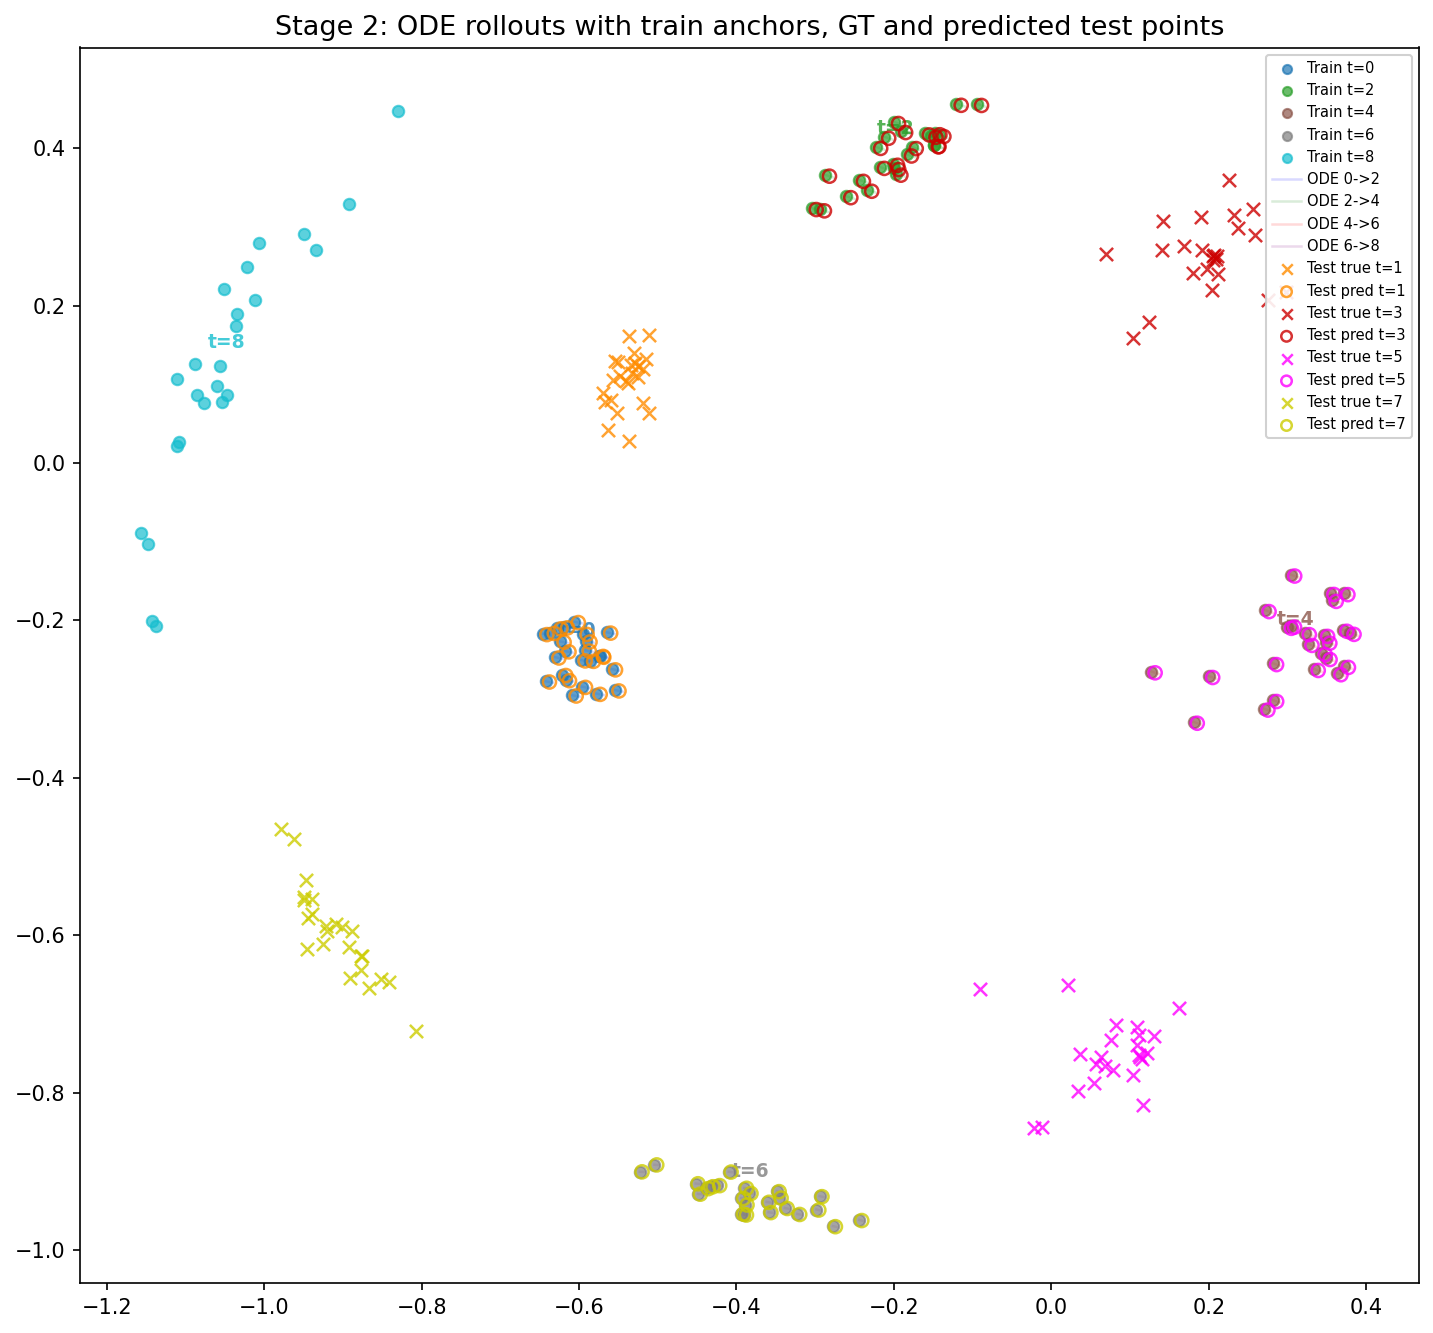

In [4]:
for method in ['pace', 'mfm']:
    print(method.upper())
    print('Checkpoints:', [p.relative_to(RUN_ROOT/method).as_posix() for p in (RUN_ROOT/method/'checkpoints').rglob('*.ckpt')])
    candidates = sorted((RUN_ROOT/method/'plots/stage2').glob('*.png'))
    if candidates: display(Image(filename=str(candidates[0]), width=800))

## Move to a full experiment

To run the configured experiment, remove the tutorial overrides:

```bash
python train.py experiment=oceans_positions_pace_ode
python train.py experiment=oceans_positions_mfm_ode
```

The default trainer expects a GPU; add `trainer=cpu` for CPU execution. Change the `experiment` to use another dataset. The current development settings and published-table discrepancies are documented in [reproducibility.md](../docs/reproducibility.md).

Next: [03 · Query a learned flow](03_inference_and_results.ipynb).